In [26]:
import pandas as pd

clusters = pd.read_csv(
    "../constants/Astroviridae_Aves_Amphibia_14072026.csv",
    sep=","
)

clusters["ID"] = clusters["ID"].str.replace("NC-", "NC_", regex=False)

annotated = pd.read_csv(
    "../constants/Astroviridae_30062026_annotated_MAstV_species.tsv",
    sep="\t",
    low_memory=False
)

host = annotated[["Accession", "Host_species"]].drop_duplicates("Accession")

result = clusters.merge(
    host,
    left_on="ID",
    right_on="Accession",
    how="left"
).drop(columns=["Accession"])

print("Всего строк:", len(result))
print("С host_species:", result["Host_species"].notna().sum())
print("Без host_species:", result["Host_species"].isna().sum())

print("\nID без host_species:")
print(
    result.loc[
        result["Host_species"].isna(),
        "ID"
    ].to_string(index=False)
)

output = "../constants/Astroviridae_Aves_Amphibia_14072026_host.csv"

result.to_csv(
    output,
    index=False
)

print("\nРезультат сохранён:")
print(output)

Всего строк: 407
С host_species: 352
Без host_species: 55

ID без host_species:
 PV793829
 PV793828
 MW588064
 MW588063
 MW588062
 OQ986679
 OQ986609
 OQ986608
 OQ986607
 OQ986677
 OQ986606
 MW826483
 MW826482
 MW385412
 MW826371
 MT138011
 MT138010
 MT138007
 MT138005
 MT138002
 MT137999
 MT137996
 MT138009
 MT137995
 MT137994
 MT137992
 MT137991
 MN920672
 MN920671
 MN920670
 MN920669
 MN920668
 MN920667
 MN920663
 MK096775
 MK096774
 MK096773
 MG661261
NC_005790
 KF753807
 KF753806
 KF753805
 KF753804
 EU143851
 EU143850
 EU143849
 EU143848
 EU143847
 EU143846
 EU143845
 EU143844
 EU143843
 AF206663
 HV511037
 AB033998

Результат сохранён:
../constants/Astroviridae_Aves_Amphibia_14072026_host.csv


In [15]:
import pandas as pd

clusters = pd.read_csv(
    "../constants/Astroviridae_Aves_Amphibia_14072026.csv",
    sep=","
)

clusters["ID"] = clusters["ID"].str.replace("NC-", "NC_", regex=False)

ids = [
    "MW588063",
    "MW588062",
    "OQ986679",
    "OQ986609",
    "OQ986608",
    "OQ986607",
    "OQ986677",
    "OQ986606",
    "MT138011",
    "MT138010",
    "MT138007",
    "MT138005",
    "MT138002",
    "MT137999",
    "MT137996",
    "MT138009",
    "MT137995",
    "MT137994",
    "MT137992",
    "MT137991",
    "MN920672",
    "MN920671",
    "MN920670",
    "MN920669",
    "MN920668",
    "MN920667",
    "MN920663",
    "MG661261",
    "NC_005790",
    "KF753807",
    "KF753806",
    "KF753805",
    "KF753804",
    "EU143851",
    "EU143850",
    "EU143849",
    "EU143848",
    "EU143847",
    "EU143846",
    "EU143845",
    "EU143844",
    "EU143843",
    "AF206663",
    "HV511037",
    "AB033998"
]

result = clusters.loc[
    clusters["ID"].isin(ids),
    ["ID", "Host"]
].copy()

print("Запрошено ID:", len(ids))
print("Найдено ID:", result["ID"].nunique())
print("Не найдено ID:", len(set(ids) - set(result["ID"])))

print("\nID без Host:")
print(
    result.loc[
        result["Host"].isna(),
        "ID"
    ].to_string(index=False)
)

missing_ids = sorted(set(ids) - set(result["ID"]))

if missing_ids:
    print("\nID, которых нет в исходной таблице:")
    print("\n".join(missing_ids))

input_taxonomy = result[["Host"]].drop_duplicates()

output = "../constants/hosts_for_taxonomy.tsv"

input_taxonomy.to_csv(
    output,
    sep="\t",
    index=False
)

print("\nФайл для taxonomy-скрипта сохранён:")
print(output)

Запрошено ID: 45
Найдено ID: 45
Не найдено ID: 0

ID без Host:
 MT138011
 MT138010
 MT138007
 MT138005
 MT138002
 MT137996
 MT138009
 MT137995
 MT137994
 MT137992
 MN920672
 MN920671
 MN920670
 MN920669
 MN920668
 MN920663
NC_005790
 HV511037

Файл для taxonomy-скрипта сохранён:
../constants/hosts_for_taxonomy.tsv


In [27]:
import pandas as pd

host = pd.read_csv(
    "../constants/Astroviridae_Aves_Amphibia_14072026_host.csv",
    sep=",",
    dtype=str
)

taxonomy = pd.read_csv(
    "../constants/hosts_taxonomy.tsv",
    sep="\t",
    dtype=str
)

taxonomy = taxonomy[
    ["host_original", "species"]
].drop_duplicates("host_original")

host = host.merge(
    taxonomy,
    how="left",
    left_on="Host",
    right_on="host_original"
)

if "Host_species" not in host.columns:
    host["Host_species"] = pd.NA

mask = (
    host["Host_species"].isna() |
    (host["Host_species"].str.strip() == "")
)

host.loc[mask, "Host_species"] = host.loc[mask, "species"]

host = host.drop(
    columns=["host_original", "species"]
)

host.to_csv(
    "../constants/Astroviridae_Aves_Amphibia_14072026_host_species.csv",
    index=False
)

In [54]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from Bio import SeqIO

fasta_file = Path("../../Astroviridae_data/Astroviridae_15102025.fasta")
csv_file = Path("../constants/Astroviridae_Aves_Amphibia_14072026.csv")
ids_file = Path("../../clade_analysis/AVES/final_files/Aves_full_ids_removed.txt")
out_dir = Path("../ORF_shift_analysis")
out_dir.mkdir(exist_ok=True)

df = pd.read_csv(csv_file, sep=None, engine="python", dtype=str)
df.columns = df.columns.str.strip()

required_columns = ["ID", "1A", "1A-strand", "1B", "1B-strand", "2", "2-strand"]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"В CSV отсутствуют колонки: {missing_columns}")

def normalize_id(value):
    return str(value).strip().split("_")[0].split(".")[0]

df["ID"] = df["ID"].apply(normalize_id)

allowed_ids = {
    normalize_id(line)
    for line in ids_file.read_text().splitlines()
    if line.strip()
}

df = df[
    df["ID"].isin(allowed_ids)
    & (df["ID"] != "HV511037")
].copy()

target_ids = set(df["ID"])

print("Строк после фильтрации:", len(df))
print("Уникальных ID после фильтрации:", df["ID"].nunique())
print("HV511037 присутствует:", "HV511037" in target_ids)

genomes = {}
for record in SeqIO.parse(fasta_file, "fasta"):
    genome_id = normalize_id(record.id)
    if genome_id in target_ids:
        genomes[genome_id] = str(record.seq).upper()

def parse_range(value):
    if pd.isna(value):
        return np.nan, np.nan
    match = re.fullmatch(r"\s*(\d+)\s*-\s*(\d+)\s*", str(value))
    if not match:
        return np.nan, np.nan
    return int(match.group(1)), int(match.group(2))

def get_strand(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    if value in {"1", "1.0", "+"}:
        return 1
    if value in {"-1", "-1.0", "-"}:
        return -1
    return np.nan

for orf in ["1A", "1B", "2"]:
    coords = df[orf].apply(parse_range)
    df[f"{orf}_start"] = coords.apply(lambda x: x[0])
    df[f"{orf}_end"] = coords.apply(lambda x: x[1])
    df[f"{orf}_strand_value"] = df[f"{orf}-strand"].apply(get_strand)
    df[f"{orf}_length_nt"] = df[f"{orf}_end"] - df[f"{orf}_start"] + 1

df["genome_length"] = df["ID"].map(
    lambda x: len(genomes[x]) if x in genomes else np.nan
)
df["genome_found"] = df["ID"].isin(genomes)

def transcript_start(row, orf):
    start = row[f"{orf}_start"]
    end = row[f"{orf}_end"]
    strand = row[f"{orf}_strand_value"]
    if pd.isna(start) or pd.isna(end) or pd.isna(strand):
        return np.nan
    return start if strand == 1 else end

for orf in ["1A", "1B", "2"]:
    df[f"{orf}_transcript_start"] = df.apply(
        lambda row: transcript_start(row, orf), axis=1
    )

df["1B_offset_nt"] = (
    df["1B_transcript_start"] - df["1A_transcript_start"]
) * df["1A_strand_value"]

df["2_offset_nt"] = (
    df["2_transcript_start"] - df["1A_transcript_start"]
) * df["1A_strand_value"]

df["1B_frame_relative"] = df["1B_offset_nt"] % 3
df["2_frame_relative"] = df["2_offset_nt"] % 3

for orf in ["1B", "2"]:
    col = f"{orf}_frame_relative"
    print(f"\nРаспределение геномов по рамкам для ORF{orf}:")
    counts = df[col].value_counts().reindex([0, 1, 2], fill_value=0)
    percentages = counts / counts.sum() * 100

    result = pd.DataFrame({
        "Рамка": counts.index,
        "Количество геномов": counts.values,
        "Процент": percentages.values.round(2)
    })

    display(result)
    print("Всего геномов:", counts.sum())

def overlap_nt(row, orf1, orf2):
    values = [
        row[f"{orf1}_start"], row[f"{orf1}_end"],
        row[f"{orf2}_start"], row[f"{orf2}_end"]
    ]
    if any(pd.isna(x) for x in values):
        return np.nan
    return max(
        0,
        min(row[f"{orf1}_end"], row[f"{orf2}_end"])
        - max(row[f"{orf1}_start"], row[f"{orf2}_start"]) + 1
    )

def gap_nt(row, orf1, orf2):
    values = [
        row[f"{orf1}_start"], row[f"{orf1}_end"],
        row[f"{orf2}_start"], row[f"{orf2}_end"]
    ]
    if any(pd.isna(x) for x in values):
        return np.nan
    if row[f"{orf1}_end"] < row[f"{orf2}_start"]:
        return row[f"{orf2}_start"] - row[f"{orf1}_end"] - 1
    if row[f"{orf2}_end"] < row[f"{orf1}_start"]:
        return row[f"{orf1}_start"] - row[f"{orf2}_end"] - 1
    return 0

for orf1, orf2 in [("1A", "1B"), ("1A", "2"), ("1B", "2")]:
    df[f"{orf1}_{orf2}_overlap_nt"] = df.apply(
        lambda row: overlap_nt(row, orf1, orf2), axis=1
    )
    df[f"{orf1}_{orf2}_gap_nt"] = df.apply(
        lambda row: gap_nt(row, orf1, orf2), axis=1
    )

def check_row(row):
    if not row["genome_found"]:
        return "genome_not_found"

    length = row["genome_length"]

    for orf in ["1A", "1B", "2"]:
        start = row[f"{orf}_start"]
        end = row[f"{orf}_end"]

        if pd.isna(start) or pd.isna(end):
            return f"{orf}_coordinates_missing"

        if start < 1 or end < start or end > length:
            return f"{orf}_coordinates_invalid"

        if pd.isna(row[f"{orf}_strand_value"]):
            return f"{orf}_strand_unknown"

    return "OK"

df["coordinate_check"] = df.apply(check_row, axis=1)

summary_columns = [
    "ID", "genome_length",
    "1A", "1B", "2",
    "1A_length_nt", "1B_length_nt", "2_length_nt",
    "1B_offset_nt", "2_offset_nt",
    "1B_frame_relative", "2_frame_relative",
    "1A_1B_overlap_nt", "1A_1B_gap_nt",
    "1A_2_overlap_nt", "1A_2_gap_nt",
    "1B_2_overlap_nt", "1B_2_gap_nt",
    "coordinate_check"
]

full_result = out_dir / "Avian_Astrovirus_ORF_shifts_full.csv"
summary_result = out_dir / "Avian_Astrovirus_ORF_shifts_summary.csv"

df.to_csv(full_result, index=False)
df[summary_columns].to_csv(summary_result, index=False)

print("\nСтрок в итоговом CSV:", len(df))
print("Уникальных ID в итоговом CSV:", df["ID"].nunique())
print("Последовательностей найдено в FASTA:", len(genomes))
print("ID без последовательности в FASTA:", len(target_ids - set(genomes)))
print("HV511037 присутствует в результатах:", "HV511037" in set(df["ID"]))

print("\nПроверка координат:")
print(df["coordinate_check"].value_counts(dropna=False))

print("\nРезультаты:")
display(df[summary_columns].head(20))

print("\nПолная таблица:", full_result.resolve())
print("Краткая таблица:", summary_result.resolve())

Строк после фильтрации: 395
Уникальных ID после фильтрации: 395
HV511037 присутствует: False

Распределение геномов по рамкам для ORF1B:


,Рамка,Количество геномов,Процент
0,0,0,0.0
1,1,0,0.0
2,2,395,100.0


Всего геномов: 395

Распределение геномов по рамкам для ORF2:


,Рамка,Количество геномов,Процент
0,0,64,16.20
1,1,82,20.76
2,2,249,63.04


Всего геномов: 395

Строк в итоговом CSV: 395
Уникальных ID в итоговом CSV: 395
Последовательностей найдено в FASTA: 395
ID без последовательности в FASTA: 0
HV511037 присутствует в результатах: False

Проверка координат:
coordinate_check
OK                        370
1A_coordinates_invalid     25
Name: count, dtype: int64

Результаты:


,ID,genome_length,1A,1B,2,1A_length_nt,1B_length_nt,2_length_nt,1B_offset_nt,2_offset_nt,1B_frame_relative,2_frame_relative,1A_1B_overlap_nt,1A_1B_gap_nt,1A_2_overlap_nt,1A_2_gap_nt,1B_2_overlap_nt,1B_2_gap_nt,coordinate_check
0,PX237222,6960,86-3098,3091-4618,4636-6682,3013,1528,2047,3005,4550,2,2,8,0,0,1537,0,17,OK
1,PV793827,7275,100-3406,3390-4938,4931-7178,3307,1549,2248,3290,4831,2,1,17,0,0,1524,8,0,OK
2,PV793829,7104,42-3228,3230-4757,4683-6879,3187,1528,2197,3188,4641,2,0,0,1,0,1454,75,0,OK
3,PV793828,7416,142-3511,3495-5046,4924-7243,3370,1552,2320,3353,4782,2,0,17,0,0,1412,123,0,OK
4,PV793826,7211,70-3358,3342-4896,4889-7124,3289,1555,2236,3272,4819,2,1,17,0,0,1530,8,0,OK
5,PV780437,7186,22-3277,3267-4818,4836-6951,3256,1552,2116,3245,4814,2,2,11,0,0,1558,0,17,OK
6,PV780436,7179,15-3270,3260-4811,4829-6944,3256,1552,2116,3245,4814,2,2,11,0,0,1558,0,17,OK
7,PV780435,7177,13-3268,3258-4809,4827-6942,3256,1552,2116,3245,4814,2,2,11,0,0,1558,0,17,OK
8,PV780434,7217,53-3308,3298-4849,4867-6982,3256,1552,2116,3245,4814,2,2,11,0,0,1558,0,17,OK
9,PP871812,7130,0-3381,3362-4922,4946-7109,3382,1561,2164,3362,4946,2,2,20,0,0,1564,0,23,1A_coordinates_invalid



Полная таблица: /Users/abagavetdinova/Desktop/lab/Astroviridae_database/data/snakemake/ORF_shift_analysis/Avian_Astrovirus_ORF_shifts_full.csv
Краткая таблица: /Users/abagavetdinova/Desktop/lab/Astroviridae_database/data/snakemake/ORF_shift_analysis/Avian_Astrovirus_ORF_shifts_summary.csv


In [43]:
import pandas as pd
from pathlib import Path

metadata_file = "../constants/Astroviridae_Aves_30042026_clusters_shorter.csv"
shifts_file = "../ORF_shift_analysis/Avian_Astrovirus_ORF_shifts_summary.csv"
output_file = "../constants/Astroviridae_Aves_30042026_clusters_shorter_shift.csv"

metadata = pd.read_csv(metadata_file, sep = ';')
shifts = pd.read_csv(shifts_file)

for df in [metadata, shifts]:
    df["ID"] = (
        df["id"].astype("string")
        .str.strip()
        .str.upper()
        .str.replace("-", "_", regex=False)
    )

shifts = shifts[["id", "2_frame_relative"]]
metadata = metadata.drop(columns=["2_frame_relative"], errors="ignore")

metadata = metadata.merge(
    shifts, on="id", how="left", validate="many_to_one", sort=False
)

metadata.to_csv(output_file, index=False)

print(f"Сохранено в: {Path(output_file).resolve()}")
print(f"Строк в основной таблице: {len(metadata)}")
print(f"Совпадений ID: {metadata['2_frame_relative'].notna().sum()}")
print(f"Без совпадений: {metadata['2_frame_relative'].isna().sum()}")

Сохранено в: /Users/abagavetdinova/Desktop/lab/Astroviridae_database/data/snakemake/constants/Astroviridae_Aves_30042026_clusters_shorter_shift.csv
Строк в основной таблице: 396
Совпадений ID: 396
Без совпадений: 0


N = 395
Среднее = 11.5063
Медиана = 11.0000
Q1 = 11.0000
Q3 = 11.0000
IQR = 0.0000


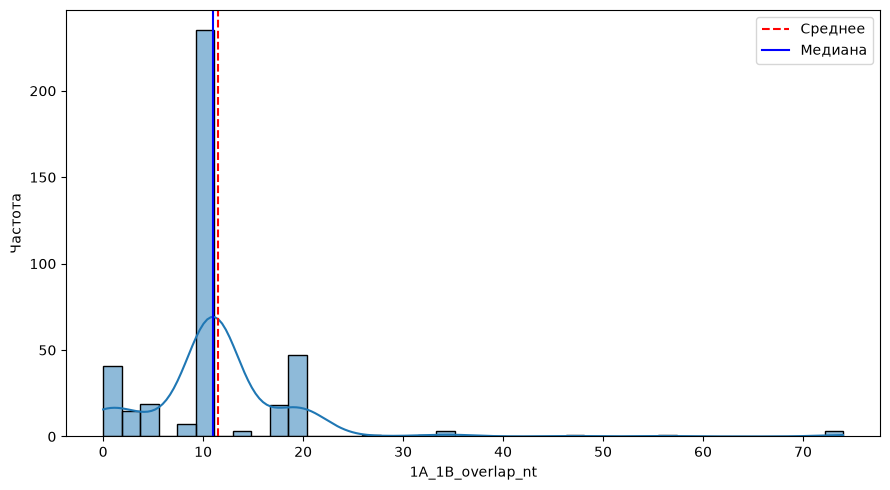

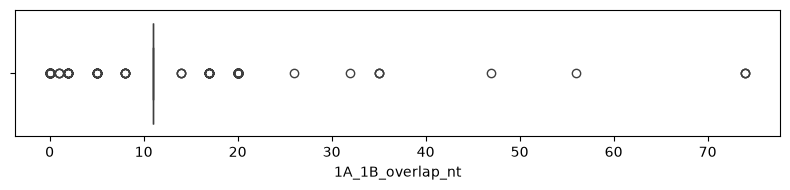

In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Чтение CSV
df = pd.read_csv('../ORF_shift_analysis/Avian_Astrovirus_ORF_shifts_summary.csv')

col = '1A_1B_overlap_nt'
x = df[col].dropna()

# Статистики
q1 = x.quantile(0.25)
q3 = x.quantile(0.75)

print(f'N = {len(x)}')
print(f'Среднее = {x.mean():.4f}')
print(f'Медиана = {x.median():.4f}')
print(f'Q1 = {q1:.4f}')
print(f'Q3 = {q3:.4f}')
print(f'IQR = {q3 - q1:.4f}')

# Распределение
plt.figure(figsize=(9, 5))
sns.histplot(x, kde=True)
plt.axvline(x.mean(), color='red', linestyle='--', label='Среднее')
plt.axvline(x.median(), color='blue', linestyle='-', label='Медиана')
plt.xlabel(col)
plt.ylabel('Частота')
plt.legend()
plt.tight_layout()
plt.savefig(f'../ORF_shift_analysis/{col}_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Boxplot
plt.figure(figsize=(8, 2))
sns.boxplot(x=x)
plt.xlabel(col)
plt.tight_layout()
plt.show()

In [ ]:
Массив скриптов для поиска a6c в нуклеотидной последовательности

In [96]:
#преобразование файла после prodigal
from pathlib import Path
import pandas as pd

input_file = Path("../ORF_shift_analysis/prodigal/first_long_orfs.csv")
output_file = Path("../ORF_shift_analysis/prodigal/first_long_orfs_coordinates.csv")

df = pd.read_csv(input_file)

result = pd.DataFrame({
    "id": df["accession"].str.split("/").str[0],
    "start": df["start"],
    "end": df["end"]
})

result.to_csv(output_file, index=False)

print(f"Обработано строк: {len(result)}")
print(f"Результат сохранён: {output_file}")

Обработано строк: 395
Результат сохранён: ../ORF_shift_analysis/prodigal/first_long_orfs_coordinates.csv


In [97]:
#поиск мотива aaaaaac
from pathlib import Path
import pandas as pd
from Bio import SeqIO

csv_file = "../ORF_shift_analysis/prodigal/first_long_orfs_coordinates.csv"
fasta_file = "../../clade_analysis/AVES/final_files/Aves_full_seq_removed_all.fasta"

def normalize_accession(value):
    accession = str(value).strip().split("/", 1)[0]
    if accession.startswith("NC_"):
        accession = accession.replace("NC_", "NC-", 1)
    return accession

df = pd.read_csv(csv_file, dtype={"id": str})
df["id"] = df["id"].apply(normalize_accession)
df["end"] = pd.to_numeric(df["end"], errors="coerce")

motif = "AAAAAAC"
motif_positions = {}

for record in SeqIO.parse(fasta_file, "fasta"):
    accession = normalize_accession(record.id)
    sequence = str(record.seq).upper()
    positions = []
    start = 0

    while True:
        pos = sequence.find(motif, start)
        if pos == -1:
            break

        motif_start = pos + 1
        motif_end = motif_start + len(motif) - 1
        positions.append((motif_start, motif_end))
        start = pos + 1

    motif_positions[accession] = positions

def select_motif(accession, orf1a_end):
    positions = motif_positions.get(accession, [])

    if len(positions) == 1:
        return positions[0]

    candidates = [
        (s, e) for s, e in positions
        if 2000 <= s <= 4000
    ]

    if not candidates or pd.isna(orf1a_end):
        return None, None

    return min(
        candidates,
        key=lambda x: abs(x[0] - orf1a_end)
    )

# Все найденные координаты
df["all_motif_start"] = df["id"].map(
    lambda x: ";".join(
        str(s) for s, e in motif_positions.get(x, [])
    )
)

df["all_motif_end"] = df["id"].map(
    lambda x: ";".join(
        str(e) for s, e in motif_positions.get(x, [])
    )
)

# Вероятный мотив по прежней логике
selected = df.apply(
    lambda row: select_motif(row["id"], row["end"]),
    axis=1
)

df["motif_start"] = [
    "" if s is None else s for s, e in selected
]

df["motif_end"] = [
    "" if e is None else e for s, e in selected
]

df.to_csv(csv_file, index=False)

found = df["motif_start"].ne("").sum()
print(f"Геномов с выбранным мотивом: {found} из {len(df)}")
print(f"Результат сохранён: {csv_file}")


Геномов с выбранным мотивом: 393 из 395
Результат сохранён: ../ORF_shift_analysis/prodigal/first_long_orfs_coordinates.csv


In [98]:
#добавление в таблицу коодинат orf1b

from pathlib import Path
import pandas as pd

csv_file = Path("../ORF_shift_analysis/prodigal/first_long_orfs_coordinates.csv")
metadata_file = Path("../constants/Astroviridae_Aves_Amphibia_14072026.csv")

def normalize_accession(value):
    accession = str(value).strip().split("/", 1)[0]
    if accession.startswith("NC_"):
        accession = accession.replace("NC_", "NC-", 1)
    return accession

df = pd.read_csv(csv_file, dtype={"id": str})
metadata = pd.read_csv(metadata_file, dtype={"ID": str})

df["id"] = df["id"].apply(normalize_accession)
metadata["ID"] = metadata["ID"].apply(normalize_accession)

metadata["1B-strand"] = metadata["1B-strand"]
metadata = metadata[["ID", "1B", "1B-strand"]].drop_duplicates("ID")
metadata = metadata.rename(columns={"ID": "id", "1B": "ORF1b"})

df = df.drop(columns=["ORF1b", "1B-strand"], errors="ignore")
df = df.merge(metadata, on="id", how="left", validate="many_to_one")

df.to_csv(csv_file, index=False)

matched = df["ORF1b"].notna().sum()
print(f"Найден ORF1b: {matched} из {len(df)} геномов")
print(f"Без координат ORF1b: {df['ORF1b'].isna().sum()}")
print(f"Результат сохранён: {csv_file}")


df = df.rename(columns={
    "start": "orf1a_start",
    "end": "orf1a_end"
})

def split_orf1b(value):
    if pd.isna(value):
        return pd.Series([None, None])

    numbers = re.findall(r"\d+", str(value))

    if len(numbers) >= 2:
        return pd.Series([int(numbers[0]), int(numbers[1])])

    return pd.Series([None, None])

df[["orf1b_start", "orf1b_end"]] = df["ORF1b"].apply(split_orf1b)
df = df.drop(columns=["ORF1b"])

df.to_csv(csv_file, index=False)

matched = df["orf1b_start"].notna().sum()
print(f"Найдены координаты ORF1b: {matched} из {len(df)} геномов")
print(f"Без координат ORF1b: {df['orf1b_start'].isna().sum()}")
print(f"Результат сохранён: {csv_file}")


Найден ORF1b: 395 из 395 геномов
Без координат ORF1b: 0
Результат сохранён: ../ORF_shift_analysis/prodigal/first_long_orfs_coordinates.csv
Найдены координаты ORF1b: 395 из 395 геномов
Без координат ORF1b: 0
Результат сохранён: ../ORF_shift_analysis/prodigal/first_long_orfs_coordinates.csv


In [99]:
#расчет дистанций от мотива до рамок
from pathlib import Path
import pandas as pd

csv_file = Path("../ORF_shift_analysis/prodigal/first_long_orfs_coordinates.csv")

df = pd.read_csv(csv_file)

for col in ["motif_start", "orf1a_end", "orf1b_start", "1B-strand"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["distance_a6c_orf1a_end"] = (
    df["orf1a_end"] - df["motif_start"]
)

df["distance_a6c_orf1b_start"] = (
    df["orf1b_start"] - df["motif_start"]
)

reverse_mask = df["1B-strand"] == -1

df.loc[reverse_mask, "distance_a6c_orf1b_start"] = (
    df.loc[reverse_mask, "motif_start"]
    - df.loc[reverse_mask, "orf1b_start"]
)

df.to_csv(csv_file, index=False)

print(f"Всего геномов: {len(df)}")
print(
    "Расстояние до конца ORF1a рассчитано: "
    f"{df['distance_a6c_orf1a_end'].notna().sum()}"
)
print(
    "Расстояние до начала ORF1b рассчитано: "
    f"{df['distance_a6c_orf1b_start'].notna().sum()}"
)
print(f"Геномов с 1b-strand = -1: {reverse_mask.sum()}")
print(f"Результат сохранён: {csv_file}")


Всего геномов: 395
Расстояние до конца ORF1a рассчитано: 393
Расстояние до начала ORF1b рассчитано: 393
Геномов с 1b-strand = -1: 1
Результат сохранён: ../ORF_shift_analysis/prodigal/first_long_orfs_coordinates.csv


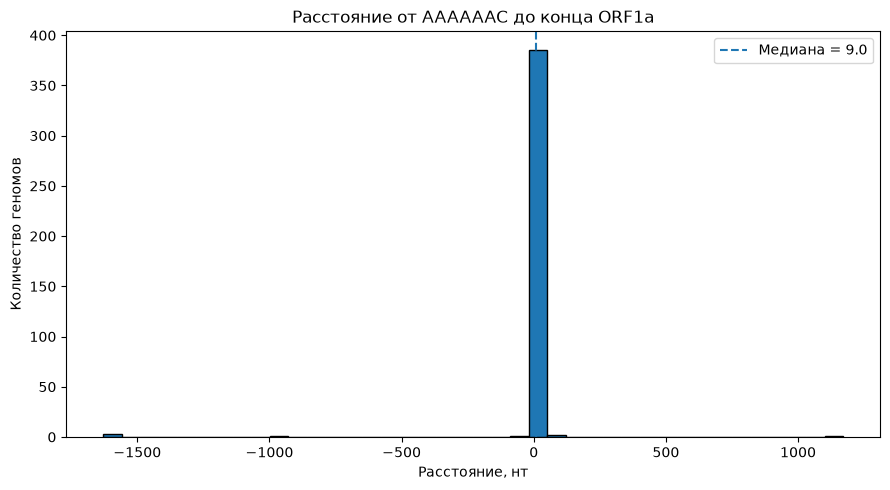


distance_a6c_orf1a_end
N = 393
Среднее = -0.83
Медиана = 9.00
Стандартное отклонение = 162.83
Минимум = -1629
Максимум = 1170
Q1 = 9.00
Q3 = 9.00


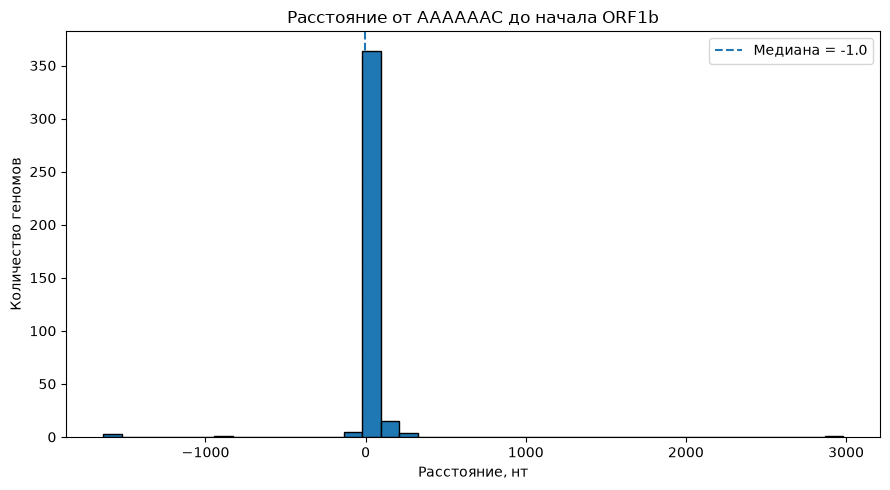


distance_a6c_orf1b_start
N = 393
Среднее = 1.33
Медиана = -1.00
Стандартное отклонение = 216.81
Минимум = -1639
Максимум = 2981
Q1 = -1.00
Q3 = -1.00


In [100]:
#построение распределний
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

csv_file = Path("../ORF_shift_analysis/prodigal/first_long_orfs_coordinates.csv")
df = pd.read_csv(csv_file)

columns = [
    ("distance_a6c_orf1a_end", "Расстояние от AAAAAAC до конца ORF1a"),
    ("distance_a6c_orf1b_start", "Расстояние от AAAAAAC до начала ORF1b")
]

for column, title in columns:
    values = pd.to_numeric(df[column], errors="coerce").dropna()

    if values.empty:
        print(f"Нет данных для {column}")
        continue

    plt.figure(figsize=(9, 5))
    plt.hist(values, bins="auto", edgecolor="black")
    plt.axvline(
        values.median(),
        linestyle="--",
        label=f"Медиана = {values.median():.1f}"
    )

    plt.title(title)
    plt.xlabel("Расстояние, нт")
    plt.ylabel("Количество геномов")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"\n{column}")
    print(f"N = {len(values)}")
    print(f"Среднее = {values.mean():.2f}")
    print(f"Медиана = {values.median():.2f}")
    print(f"Стандартное отклонение = {values.std():.2f}")
    print(f"Минимум = {values.min():.0f}")
    print(f"Максимум = {values.max():.0f}")
    print(f"Q1 = {values.quantile(0.25):.2f}")
    print(f"Q3 = {values.quantile(0.75):.2f}")
